In [1]:
import pandas as pd
import numpy as np

# Load cleaned transaction dataset
DATA_FILE = "../data/clean/transactions_clean.parquet"

transactions = pd.read_parquet(DATA_FILE)

# Recreate transaction line value
transactions["line_value"] = (
    transactions["Quantity"] * transactions["Price"]
)

print("Dataset loaded successfully!")
print("Dataset dimensions:", transactions.shape)
print("Unique identified customers:",
      transactions["Customer ID"].nunique())
print("Transaction date range:",
      transactions["InvoiceDate"].min(),
      "to",
      transactions["InvoiceDate"].max())

Dataset loaded successfully!
Dataset dimensions: (1041449, 14)
Unique identified customers: 5942
Transaction date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [2]:
# Retain identified customers and relevant transaction types
revenue_transactions = transactions[
    transactions["Customer ID"].notna()
    & transactions["line_type"].isin(["product", "adjustment"])
].copy()

# Calculate customer-level revenue by transaction type
customer_revenue = (
    revenue_transactions
    .pivot_table(
        index="Customer ID",
        columns="line_type",
        values="line_value",
        aggfunc="sum",
        fill_value=0
    )
    .reindex(
        transactions["Customer ID"].dropna().unique(),
        fill_value=0
    )
    .reset_index()
)

# Calculate net revenue
customer_revenue["net_revenue"] = (
    customer_revenue["product"]
    + customer_revenue["adjustment"]
)

# Rename columns
customer_revenue = customer_revenue.rename(columns={
    "product": "product_revenue",
    "adjustment": "adjustment_value"
})

print("Customer revenue table dimensions:",
      customer_revenue.shape)

print("Unique customers:",
      customer_revenue["Customer ID"].nunique())

print("\nRevenue summary:")
display(
    customer_revenue[
        ["product_revenue", "adjustment_value", "net_revenue"]
    ].describe()
)

display(customer_revenue.head(10))

Customer revenue table dimensions: (5942, 4)
Unique customers: 5942

Revenue summary:


line_type,product_revenue,adjustment_value,net_revenue
count,5942.000000,5942.000000,5942.000000
mean,2762.021429,-32.874731,2729.146698
std,13726.998907,703.331745,13631.874234
min,-1343.240000,-38970.000000,-25111.090000
25%,320.742500,0.000000,320.115000
50%,825.725000,0.000000,820.800000
75%,2145.925000,0.000000,2142.195000
max,578408.640000,3610.500000,570380.610000


line_type,Customer ID,adjustment_value,product_revenue,net_revenue
0,13085,-830.12,2289.58,1459.46
1,13078,0.00,28369.44,28369.44
2,15362,0.00,613.08,613.08
3,18102,-8028.03,578408.64,570380.61
4,12682,0.00,20656.52,20656.52
5,18087,848.00,13563.62,14411.62
6,13635,0.00,2948.22,2948.22
7,14110,0.00,12959.60,12959.60
8,12636,0.00,0.00,0.00
9,17519,0.00,4769.22,4769.22


In [3]:
# Calculate total revenue directly from source transactions
source_product_revenue = revenue_transactions.loc[
    revenue_transactions["line_type"] == "product",
    "line_value"
].sum()

source_adjustment_value = revenue_transactions.loc[
    revenue_transactions["line_type"] == "adjustment",
    "line_value"
].sum()

source_net_revenue = revenue_transactions["line_value"].sum()

# Calculate totals from customer revenue table
table_product_revenue = customer_revenue["product_revenue"].sum()
table_adjustment_value = customer_revenue["adjustment_value"].sum()
table_net_revenue = customer_revenue["net_revenue"].sum()

# Display reconciliation
reconciliation = pd.DataFrame({
    "Source transactions": [
        source_product_revenue,
        source_adjustment_value,
        source_net_revenue
    ],
    "Customer revenue table": [
        table_product_revenue,
        table_adjustment_value,
        table_net_revenue
    ]
}, index=[
    "Product revenue",
    "Adjustment value",
    "Net revenue"
])

reconciliation["Difference"] = (
    reconciliation["Customer revenue table"]
    - reconciliation["Source transactions"]
)

display(reconciliation.round(2))

# Additional customer checks
print("\nCustomers with negative net revenue:",
      (customer_revenue["net_revenue"] < 0).sum())

print("Customers with zero net revenue:",
      (customer_revenue["net_revenue"] == 0).sum())

# Assertions
assert np.isclose(source_product_revenue, table_product_revenue)
assert np.isclose(source_adjustment_value, table_adjustment_value)
assert np.isclose(source_net_revenue, table_net_revenue)

print("\nAll revenue reconciliation checks passed!")

,Source transactions,Customer revenue table,Difference
Product revenue,16411931.33,16411931.33,-0.0
Adjustment value,-195341.65,-195341.65,-0.0
Net revenue,16216589.68,16216589.68,-0.0



Customers with negative net revenue: 84
Customers with zero net revenue: 16

All revenue reconciliation checks passed!


In [4]:
# Rank customers by net revenue, highest first
customer_revenue_ranked = (
    customer_revenue
    .sort_values("net_revenue", ascending=False)
    .reset_index(drop=True)
)

# Calculate cumulative revenue and customer share
total_net_revenue = customer_revenue_ranked["net_revenue"].sum()

customer_revenue_ranked["cumulative_revenue"] = (
    customer_revenue_ranked["net_revenue"].cumsum()
)

customer_revenue_ranked["cumulative_revenue_share"] = (
    customer_revenue_ranked["cumulative_revenue"]
    / total_net_revenue * 100
)

customer_revenue_ranked["customer_share"] = (
    np.arange(1, len(customer_revenue_ranked) + 1)
    / len(customer_revenue_ranked) * 100
)

# Define concentration groups
top_10_pct = int(np.ceil(len(customer_revenue_ranked) * 0.10))
top_20_pct = int(np.ceil(len(customer_revenue_ranked) * 0.20))

# Calculate concentration summary
concentration_summary = pd.DataFrame({
    "Customer group": [
        "Top 10% of customers",
        "Top 20% of customers",
        "Top 50 customers",
        "Top 100 customers"
    ],
    "Number of customers": [
        top_10_pct,
        top_20_pct,
        50,
        100
    ],
    "Net revenue": [
        customer_revenue_ranked.head(top_10_pct)["net_revenue"].sum(),
        customer_revenue_ranked.head(top_20_pct)["net_revenue"].sum(),
        customer_revenue_ranked.head(50)["net_revenue"].sum(),
        customer_revenue_ranked.head(100)["net_revenue"].sum()
    ]
})

concentration_summary["Revenue contribution (%)"] = (
    concentration_summary["Net revenue"]
    / total_net_revenue * 100
)

concentration_summary["Customer contribution (%)"] = (
    concentration_summary["Number of customers"]
    / len(customer_revenue_ranked) * 100
)

display(
    concentration_summary.style.format({
        "Net revenue": "£{:,.2f}",
        "Revenue contribution (%)": "{:.2f}%",
        "Customer contribution (%)": "{:.2f}%"
    })
)

print("Total identified customers:", len(customer_revenue_ranked))
print("Total net revenue:", f"£{total_net_revenue:,.2f}")

,Customer group,Number of customers,Net revenue,Revenue contribution (%),Customer contribution (%)
0,Top 10% of customers,595,"£10,333,364.44",63.72%,10.01%
1,Top 20% of customers,1189,"£12,549,395.35",77.39%,20.01%
2,Top 50 customers,50,"£4,817,292.88",29.71%,0.84%
3,Top 100 customers,100,"£5,971,307.16",36.82%,1.68%


Total identified customers: 5942
Total net revenue: £16,216,589.68


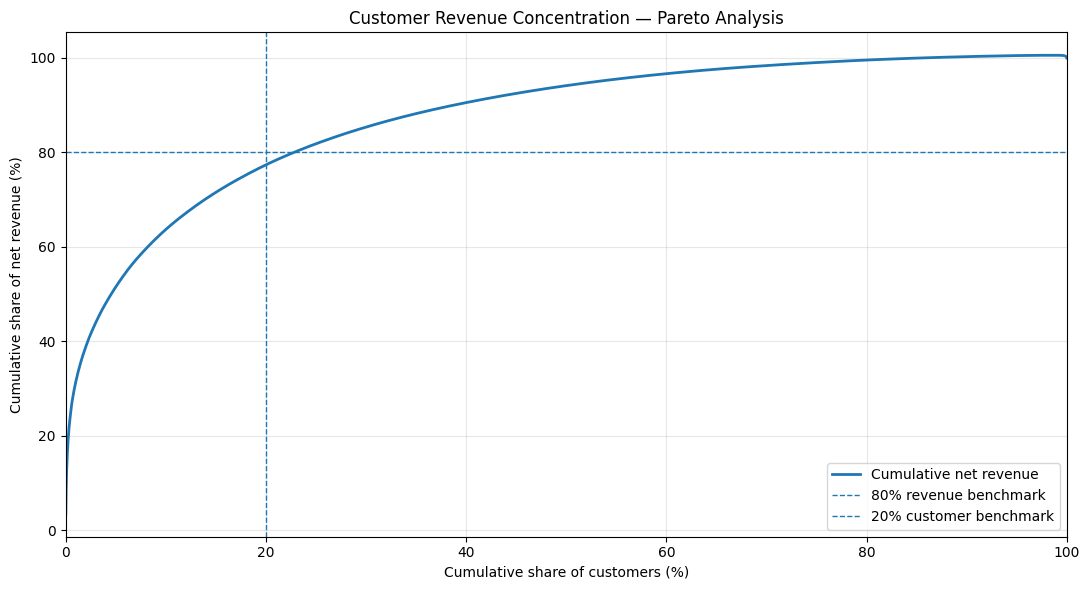

In [5]:
import matplotlib.pyplot as plt

# Create Pareto chart
plt.figure(figsize=(11, 6))

plt.plot(
    customer_revenue_ranked["customer_share"],
    customer_revenue_ranked["cumulative_revenue_share"],
    linewidth=2,
    label="Cumulative net revenue"
)

# Reference lines for the 80/20 benchmark
plt.axhline(
    80,
    linestyle="--",
    linewidth=1,
    label="80% revenue benchmark"
)

plt.axvline(
    20,
    linestyle="--",
    linewidth=1,
    label="20% customer benchmark"
)

plt.xlabel("Cumulative share of customers (%)")
plt.ylabel("Cumulative share of net revenue (%)")
plt.title("Customer Revenue Concentration — Pareto Analysis")

plt.xlim(0, 100)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
# Filter identified customers and relevant transaction types
period_transactions = transactions[
    transactions["Customer ID"].notna()
    & transactions["line_type"].isin(["product", "adjustment"])
].copy()

# Define two equal 12-month periods
period_1_start = pd.Timestamp("2009-12-01")
period_1_end = pd.Timestamp("2010-11-30 23:59:59")

period_2_start = pd.Timestamp("2010-12-01")
period_2_end = pd.Timestamp("2011-11-30 23:59:59")

# Assign transactions to periods
period_transactions["period"] = np.select(
    [
        period_transactions["InvoiceDate"].between(
            period_1_start, period_1_end
        ),
        period_transactions["InvoiceDate"].between(
            period_2_start, period_2_end
        )
    ],
    [
        "Period 1",
        "Period 2"
    ],
    default="Outside comparison"
)

# Keep only the two comparison periods
period_transactions = period_transactions[
    period_transactions["period"] != "Outside comparison"
].copy()

# Check coverage
print("Period 1 transactions:",
      (period_transactions["period"] == "Period 1").sum())

print("Period 2 transactions:",
      (period_transactions["period"] == "Period 2").sum())

print("Customers in Period 1:",
      period_transactions.loc[
          period_transactions["period"] == "Period 1",
          "Customer ID"
      ].nunique())

print("Customers in Period 2:",
      period_transactions.loc[
          period_transactions["period"] == "Period 2",
          "Customer ID"
      ].nunique())

print("Comparison date range:",
      period_transactions["InvoiceDate"].min(),
      "to",
      period_transactions["InvoiceDate"].max())

Period 1 transactions: 401769
Period 2 transactions: 387847
Customers in Period 1: 4330
Customers in Period 2: 4331
Comparison date range: 2009-12-01 07:45:00 to 2011-11-30 17:42:00


In [7]:
# Aggregate net revenue by customer and period
period_customer_revenue = (
    period_transactions
    .groupby(["period", "Customer ID"])
    .agg(
        net_revenue=("line_value", "sum")
    )
    .reset_index()
)

# Function to calculate concentration metrics
def calculate_period_concentration(group):

    group = group.sort_values(
        "net_revenue", ascending=False
    ).reset_index(drop=True)

    total_revenue = group["net_revenue"].sum()
    customer_count = len(group)

    top_10 = int(np.ceil(customer_count * 0.10))
    top_20 = int(np.ceil(customer_count * 0.20))

    return {
        "Customers": customer_count,
        "Total net revenue": total_revenue,
        "Top 10% revenue share": (
            group.head(top_10)["net_revenue"].sum()
            / total_revenue * 100
        ),
        "Top 20% revenue share": (
            group.head(top_20)["net_revenue"].sum()
            / total_revenue * 100
        ),
        "Top 50 revenue share": (
            group.head(50)["net_revenue"].sum()
            / total_revenue * 100
        ),
        "Top 100 revenue share": (
            group.head(100)["net_revenue"].sum()
            / total_revenue * 100
        )
    }

# Calculate results for both periods
period_results = pd.DataFrame({
    period: calculate_period_concentration(
        data
    )
    for period, data in period_customer_revenue.groupby("period")
}).T

display(
    period_results.style.format({
        "Total net revenue": "£{:,.2f}",
        "Top 10% revenue share": "{:.2f}%",
        "Top 20% revenue share": "{:.2f}%",
        "Top 50 revenue share": "{:.2f}%",
        "Top 100 revenue share": "{:.2f}%"
    })
)

,Customers,Total net revenue,Top 10% revenue share,Top 20% revenue share,Top 50 revenue share,Top 100 revenue share
Period 1,4330.000000,"£7,994,008.04",60.38%,74.28%,30.27%,38.21%
Period 2,4331.000000,"£7,883,458.58",59.98%,73.76%,31.25%,38.45%


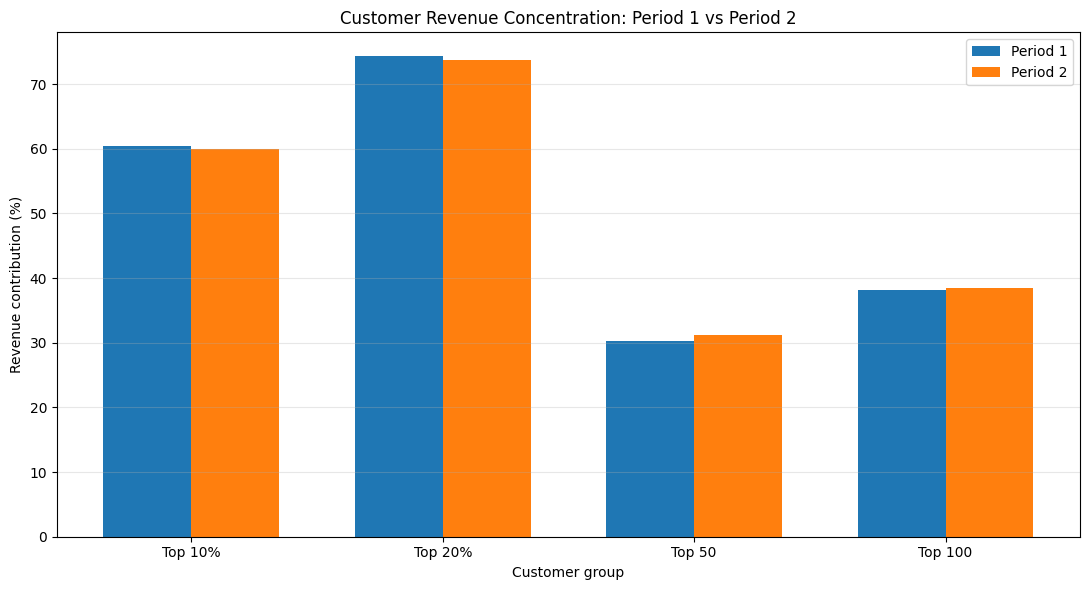

In [8]:
import matplotlib.pyplot as plt

metrics = [
    "Top 10% revenue share",
    "Top 20% revenue share",
    "Top 50 revenue share",
    "Top 100 revenue share"
]

period_1_values = period_results.loc["Period 1", metrics]
period_2_values = period_results.loc["Period 2", metrics]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    period_1_values,
    width,
    label="Period 1"
)

plt.bar(
    x + width / 2,
    period_2_values,
    width,
    label="Period 2"
)

plt.xticks(
    x,
    ["Top 10%", "Top 20%", "Top 50", "Top 100"]
)

plt.ylabel("Revenue contribution (%)")
plt.xlabel("Customer group")
plt.title("Customer Revenue Concentration: Period 1 vs Period 2")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# Rank customers separately within each period
period_ranked = period_customer_revenue.copy()

period_ranked["revenue_rank"] = (
    period_ranked
    .groupby("period")["net_revenue"]
    .rank(method="first", ascending=False)
)

# Extract top 100 customers for each period
top_100_p1 = set(
    period_ranked[
        (period_ranked["period"] == "Period 1")
        & (period_ranked["revenue_rank"] <= 100)
    ]["Customer ID"]
)

top_100_p2 = set(
    period_ranked[
        (period_ranked["period"] == "Period 2")
        & (period_ranked["revenue_rank"] <= 100)
    ]["Customer ID"]
)

# Compare customer overlap
common_customers = top_100_p1.intersection(top_100_p2)
period1_only = top_100_p1 - top_100_p2
period2_only = top_100_p2 - top_100_p1

print("Top 100 customers in Period 1:", len(top_100_p1))
print("Top 100 customers in Period 2:", len(top_100_p2))
print("Customers present in both periods:", len(common_customers))
print("Customers only in Period 1:", len(period1_only))
print("Customers only in Period 2:", len(period2_only))

print(
    "\nTop 100 customer retention rate:",
    f"{len(common_customers) / 100 * 100:.2f}%"
)

print(
    "Top 100 customer replacement rate:",
    f"{len(period2_only) / 100 * 100:.2f}%"
)

Top 100 customers in Period 1: 100
Top 100 customers in Period 2: 100
Customers present in both periods: 63
Customers only in Period 1: 37
Customers only in Period 2: 37

Top 100 customer retention rate: 63.00%
Top 100 customer replacement rate: 37.00%


In [10]:
# Create customer cohorts
customer_cohorts = {
    "Retained": common_customers,
    "Exited": period1_only,
    "New entrants": period2_only
}

# Create customer-period revenue table
cohort_revenue = (
    period_customer_revenue
    .pivot(
        index="Customer ID",
        columns="period",
        values="net_revenue"
    )
    .fillna(0)
)

# Calculate revenue generated by each cohort in both periods
cohort_summary = []

for cohort, customers in customer_cohorts.items():

    cohort_data = cohort_revenue.loc[
        cohort_revenue.index.isin(customers)
    ]

    cohort_summary.append({
        "Customer group": cohort,
        "Customers": len(customers),
        "Period 1 revenue": cohort_data["Period 1"].sum(),
        "Period 2 revenue": cohort_data["Period 2"].sum()
    })

cohort_summary = pd.DataFrame(cohort_summary)

# Calculate revenue contribution in each period
period1_total = period_customer_revenue.loc[
    period_customer_revenue["period"] == "Period 1",
    "net_revenue"
].sum()

period2_total = period_customer_revenue.loc[
    period_customer_revenue["period"] == "Period 2",
    "net_revenue"
].sum()

cohort_summary["Period 1 revenue share (%)"] = (
    cohort_summary["Period 1 revenue"] / period1_total * 100
)

cohort_summary["Period 2 revenue share (%)"] = (
    cohort_summary["Period 2 revenue"] / period2_total * 100
)

display(
    cohort_summary.style.format({
        "Period 1 revenue": "£{:,.2f}",
        "Period 2 revenue": "£{:,.2f}",
        "Period 1 revenue share (%)": "{:.2f}%",
        "Period 2 revenue share (%)": "{:.2f}%"
    })
)

,Customer group,Customers,Period 1 revenue,Period 2 revenue,Period 1 revenue share (%),Period 2 revenue share (%)
0,Retained,63,"£2,418,643.42","£2,499,441.02",30.26%,31.70%
1,Exited,37,"£635,502.81","£134,276.71",7.95%,1.70%
2,New entrants,37,"£185,860.93","£531,911.63",2.33%,6.75%


In [11]:
# Calculate revenue changes by cohort
cohort_summary["Revenue change"] = (
    cohort_summary["Period 2 revenue"]
    - cohort_summary["Period 1 revenue"]
)

cohort_summary["Revenue change (%)"] = np.where(
    cohort_summary["Period 1 revenue"] != 0,
    (
        cohort_summary["Revenue change"]
        / cohort_summary["Period 1 revenue"]
    ) * 100,
    np.nan
)

display(
    cohort_summary[
        [
            "Customer group",
            "Customers",
            "Period 1 revenue",
            "Period 2 revenue",
            "Revenue change",
            "Revenue change (%)"
        ]
    ].style.format({
        "Period 1 revenue": "£{:,.2f}",
        "Period 2 revenue": "£{:,.2f}",
        "Revenue change": "£{:,.2f}",
        "Revenue change (%)": "{:+.2f}%"
    })
)

,Customer group,Customers,Period 1 revenue,Period 2 revenue,Revenue change,Revenue change (%)
0,Retained,63,"£2,418,643.42","£2,499,441.02","£80,797.60",+3.34%
1,Exited,37,"£635,502.81","£134,276.71","£-501,226.10",-78.87%
2,New entrants,37,"£185,860.93","£531,911.63","£346,050.70",+186.19%
